# code_106 · Normalization and controlled training recipes

**Book:** section 21.4. A self-contained neural-training laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_21_GUIDE.md), [run evidence](../CHAPTER_21_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_106).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2206;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2206


<a id="recipe"></a>
 ## Change one declared part of the recipe
 Generate forty buildings × eight sensor records, with whole-building training/development/final splits 24/8/8. Fit input standardization on the 192 training records. Six fixed recipes share a two-layer width-32 ReLU MLP and precomputed mini-batch orders: AdamW baseline, layer normalization, batch normalization, layer normalization plus dropout 0.2, SGD with momentum, and AdamW with a cosine schedule. AdamW uses rate 0.01/decay 0.01; SGD rate 0.05/momentum 0.9/decay 0.01. Each has at most 120 epochs, batch size 32 and patience 15 based on development MSE. Restore each recipe's best development checkpoint; report every final result without final-driven selection.


,recipe,best_epoch,epochs_run,best_development_MSE,final_MSE
0,Base,9,24,0.122136,0.187939
1,LN,38,53,0.150077,0.202729
2,BN,8,23,0.135010,0.204270
3,LN+drop,25,40,0.126994,0.193323
4,SGD,17,32,0.120325,0.157452
5,Cosine,9,24,0.122288,0.187604


Unstable run: loss exceeds declared 1e8 health limit


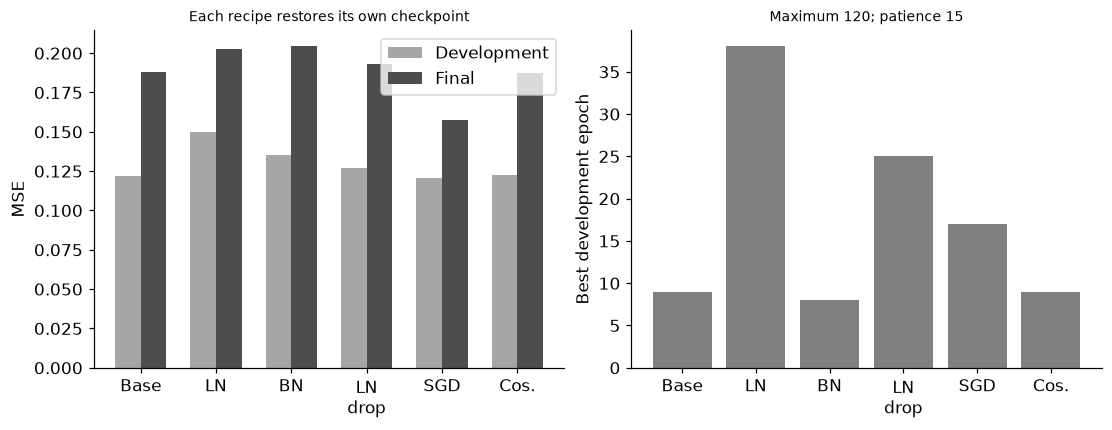

In [2]:
import copy
from sklearn.preprocessing import StandardScaler
building=np.repeat(np.arange(40),8);raw=.5*rng.normal(size=(40,8))[building]+rng.normal(size=(320,8));target=.6*np.sin(raw[:,0])+.5*raw[:,1]*raw[:,2]+.2*raw[:,3]+.2*rng.normal(size=40)[building]+rng.normal(0,.15,320)
train=building<24;dev=(building>=24)&(building<32);final=building>=32
scaler=StandardScaler().fit(raw[train]);x=torch.tensor(scaler.transform(raw));y=torch.tensor(target)[:,None];train_x=x[train];train_y=y[train]
orders=[rng.permutation(192) for _ in range(120)]
recipes=[('Base','none',0.,'adamw',False),('LN','layer',0.,'adamw',False),('BN','batch',0.,'adamw',False),('LN+drop','layer',.2,'adamw',False),('SGD','none',0.,'sgd',False),('Cosine','none',0.,'adamw',True)]
def build_model(normalization='none',dropout=0.):
    torch.manual_seed(SEED);parts=[]
    for incoming in [8,32]:
        parts.append(nn.Linear(incoming,32))
        if normalization=='layer':parts.append(nn.LayerNorm(32))
        if normalization=='batch':parts.append(nn.BatchNorm1d(32))
        parts.extend([nn.ReLU(),nn.Dropout(dropout)])
    parts.append(nn.Linear(32,1));return nn.Sequential(*parts)
fitted={};histories={};rows=[]
for name,normalization,dropout,optimizer_name,scheduled in recipes:
    model=build_model(normalization,dropout);optimizer=torch.optim.AdamW(model.parameters(),lr=.01,weight_decay=.01) if optimizer_name=='adamw' else torch.optim.SGD(model.parameters(),lr=.05,momentum=.9,weight_decay=.01)
    schedule=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=120) if scheduled else None
    best=float('inf');best_state=None;stale=0;history=[]
    for epoch in range(120):
        model.train();loss_sum=0.;norms=[]
        for start in range(0,192,32):
            batch=orders[epoch][start:start+32];optimizer.zero_grad();loss=torch.mean((model(train_x[batch])-train_y[batch])**2);loss.backward();norm=float(torch.sqrt(sum(torch.sum(p.grad**2) for p in model.parameters())))
            assert np.isfinite(norm) and torch.isfinite(loss);norms.append(norm);optimizer.step();loss_sum+=float(loss.detach())*len(batch)
        model.eval()
        with torch.no_grad():validation=float(torch.mean((model(x[dev])-y[dev])**2))
        history.append({'epoch':epoch+1,'train_MSE':loss_sum/192,'development_MSE':validation,'mean_gradient_norm':float(np.mean(norms)),'learning_rate':float(optimizer.param_groups[0]['lr'])})
        if validation<best-1e-8:best=validation;best_epoch=epoch+1;best_state=copy.deepcopy(model.state_dict());stale=0
        else:stale+=1
        if schedule:schedule.step()
        if stale>=15:break
    model.load_state_dict(best_state);model.eval()
    with torch.no_grad():final_mse=float(torch.mean((model(x[final])-y[final])**2))
    rows.append({'recipe':name,'best_epoch':best_epoch,'epochs_run':len(history),'best_development_MSE':best,'final_MSE':final_mse});fitted[name]=model;histories[name]=history
# Clone diagnostic models, so batch-statistic probes do not alter fitted checkpoints.
query=x[final][:1];context_a=torch.cat([query,train_x[:7]]);context_b=torch.cat([query,train_x[:7]+3])
with torch.no_grad():
    bn_a=copy.deepcopy(fitted['BN']).train();bn_b=copy.deepcopy(fitted['BN']).train();bn_train_difference=float(torch.abs(bn_a(context_a)[0]-bn_b(context_b)[0]).item())
    bn=fitted['BN'].eval();bn_eval_difference=float(torch.abs(bn(query)[0]-bn(context_b)[0]).item());assert bn_eval_difference<1e-10
    ln=fitted['LN'].eval();ln_difference=float(torch.abs(ln(query)[0]-ln(context_b)[0]).item());assert ln_difference<1e-10
    dropout_model=copy.deepcopy(fitted['LN+drop']).train();drop_train_difference=float(torch.linalg.vector_norm(dropout_model(train_x[:8])-dropout_model(train_x[:8])))
    dropout_model.eval();torch.testing.assert_close(dropout_model(train_x[:8]),dropout_model(train_x[:8]),atol=0,rtol=0)
assert bn_train_difference>1e-8 and drop_train_difference>0
unstable=build_model();unstable_optimizer=torch.optim.SGD(unstable.parameters(),lr=20.);bad_history=[];health_stop='fixed budget'
for step in range(20):
    unstable_optimizer.zero_grad();loss=torch.mean((unstable(train_x)-train_y)**2)
    if not torch.isfinite(loss):health_stop='nonfinite loss';break
    loss.backward();norm=float(torch.sqrt(sum(torch.sum(p.grad**2) for p in unstable.parameters())))
    if not np.isfinite(norm):health_stop='nonfinite gradient';break
    unstable.eval()
    with torch.no_grad():validation=float(torch.mean((unstable(x[dev])-y[dev])**2))
    bad_history.append({'update':step,'train_MSE':float(loss.detach()),'development_MSE':validation,'gradient_norm':norm})
    if float(loss.detach())>1e8:health_stop='loss exceeds declared 1e8 health limit';break
    unstable_optimizer.step();unstable.train()
assert health_stop!='fixed budget'
RESULTS.update(recipes=rows,histories=histories,unstable_history=bad_history,unstable_stop=health_stop,batchnorm_train_context_difference=bn_train_difference,batchnorm_eval_context_difference=bn_eval_difference,layernorm_eval_context_difference=ln_difference,dropout_train_repeat_difference=drop_train_difference,split_buildings=[24,8,8])
display(pd.DataFrame(rows));print('Unstable run:',health_stop)
fig,axes=plt.subplots(1,2,figsize=(10,3.8));xx=np.arange(len(rows))
axes[0].bar(xx-.17,[r['best_development_MSE'] for r in rows],.34,color='.65',label='Development');axes[0].bar(xx+.17,[r['final_MSE'] for r in rows],.34,color='.3',label='Final');axes[0].set(xticks=xx,xticklabels=['Base','LN','BN','LN\ndrop','SGD','Cos.'],ylabel='MSE',title='Each recipe restores its own checkpoint');axes[0].legend()
axes[1].bar(xx,[r['best_epoch'] for r in rows],color='.5');axes[1].set(xticks=xx,xticklabels=['Base','LN','BN','LN\ndrop','SGD','Cos.'],ylabel='Best development epoch',title='Maximum 120; patience 15');plt.show()


<a id="health"></a>
 ## Training mode is an inference contract
 BatchNorm uses batch statistics while training and fitted running statistics during evaluation. LayerNorm normalizes within each record's declared feature dimensions in both modes. Dropout changes repeated training calls and becomes identity at evaluation. no_grad does not switch module mode. The deliberately unstable learning-rate-20 run uses the baseline architecture and a declared health stop; it is not hidden inside an apparently successful fit. Its full-batch updates and normal mini-batch epochs have different horizontal units. A change in optimizer can require its own tuning budget; these six fixed recipes do not identify a universal winner.


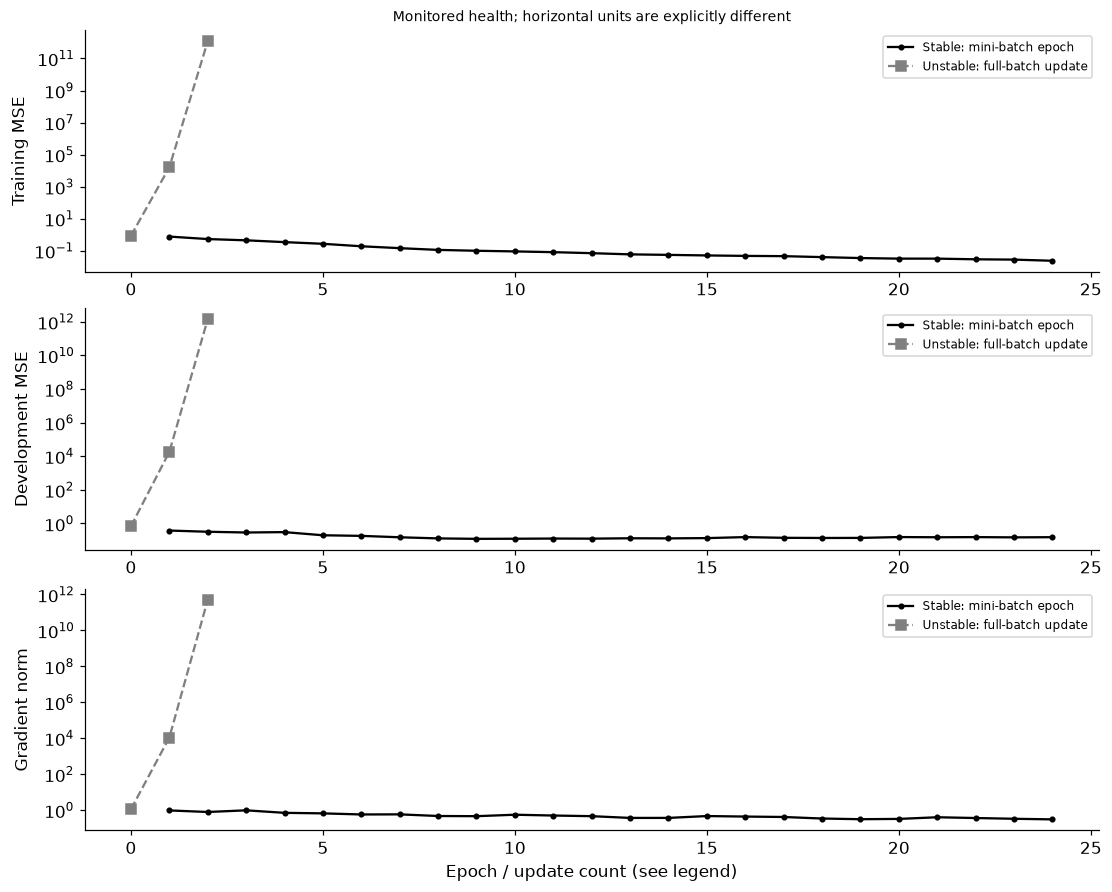

In [3]:
fig,axes=plt.subplots(3,1,figsize=(10,8));stable=histories['Base']
for ax,key,bad_key,label in [(axes[0],'train_MSE','train_MSE','Training MSE'),(axes[1],'development_MSE','development_MSE','Development MSE'),(axes[2],'mean_gradient_norm','gradient_norm','Gradient norm')]:
    ax.semilogy([r['epoch'] for r in stable],[max(r[key],1e-14) for r in stable],'o-',markersize=3,color='black',label='Stable: mini-batch epoch')
    ax.semilogy([r['update'] for r in bad_history],[max(r[bad_key],1e-14) for r in bad_history],'s--',color='.5',label='Unstable: full-batch update');ax.set(ylabel=label);ax.legend(fontsize=8)
axes[0].set_title('Monitored health; horizontal units are explicitly different');axes[-1].set_xlabel('Epoch / update count (see legend)');plt.show()
assert all(np.isfinite(r['final_MSE']) for r in rows)


In [4]:
summary={'example_id':'code_106','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual AdamW/SGD ablations', 'batch and layer normalization', 'dropout train/eval contracts', 'development early stopping', 'controlled instability dashboard'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual AdamW/SGD ablations", "batch and layer normalization", "dropout train/eval contracts", "development early stopping", "controlled instability dashboard"], "elapsed_seconds": 1.17, "example_id": "code_106", "hardware": "Darwin arm64 CPU", "results": {"batchnorm_eval_context_difference": 1.6653345369377348e-16, "batchnorm_train_context_difference": 1.502284438646759, "dropout_train_repeat_difference": 1.7998832817958124, "histories": {"BN": [{"development_MSE": 0.4414772558501253, "epoch": 1, "learning_rate": 0.01, "mean_gradient_norm": 2.3082565011634277, "train_MSE": 0.6888453410695708}, {"development_MSE": 0.39410820705332267, "epoch": 2, "learning_rate": 0.01, "mean_gradient_norm": 1.8438029483003053, "train_MSE": 0.41790285917567155}, {"development_MSE": 0.26781587940845086, "epoch": 3, "learning_rate": 0.01, "mean_gradient_norm": 1.5767097335547196, "train_MSE": 0.30130694015649856}, {"development_MSE": 0.1794958133064934, "e